In [ ]:
import sdv
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn import tree
from sklearn.metrics import *
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier,
                            IsolationForest, GradientBoostingClassifier, BaggingClassifier)

from imblearn.over_sampling import SMOTENC
from xgboost import XGBClassifier

RANDOM_STATE = 42

# 1. Comedy Show

In [2]:
df = pd.read_csv("../1.decision_tree_comedy_show/data.csv")
df

,Age,Experience,Rank,Nationality,Go
0,36,10,9,UK,NO
1,42,12,4,USA,NO
2,23,4,6,N,NO
3,52,4,4,USA,NO
4,43,21,8,USA,YES
5,44,14,5,UK,NO
6,66,3,7,N,YES
7,35,14,9,UK,YES
8,52,13,7,N,YES
9,35,5,9,N,YES


### A. Generate synthetic rows with SDV

In [3]:
metadata = sdv.metadata.Metadata.detect_from_dataframes(data={'comedian': df})
synthesizer = sdv.single_table.GaussianCopulaSynthesizer(metadata)
synthesizer.fit({'comedian': df})
synthetic_data = synthesizer.sample(num_rows=100)['comedian']
df_augmented = pd.concat([df, synthetic_data],ignore_index=True)

df_augmented['Nationality'] = df_augmented['Nationality'].map({'UK': 0, 'USA': 1, 'N': 2})
df_augmented['Go'] = df_augmented['Go'].map({'YES': 1, 'NO': 0})

display(df_augmented)

/home/mehrdad/.local/lib/python3.10/site-packages/sdv/single_table/base.py:136: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(


,Age,Experience,Rank,Nationality,Go
0,36,10,9,0,0
1,42,12,4,1,0
2,23,4,6,2,0
3,52,4,4,1,0
4,43,21,8,1,1
...,...,...,...,...,...
108,41,10,4,1,1
109,21,5,5,1,1
110,21,10,8,1,0
111,43,18,8,0,1


In [4]:
features = ['Age', 'Experience', 'Rank', 'Nationality']

X = df_augmented[features]
y = df_augmented['Go']

### B. Train models

In [5]:
gini_tree = DecisionTreeClassifier(criterion="gini", random_state=RANDOM_STATE)
entropy_tree = DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_STATE)

gini_tree.fit(X, y)
entropy_tree.fit(X, y)

,criterion,'entropy'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


#### Differences in the tree structure

In [6]:
def root_split(model):
    feature_id = model.tree_.feature[0]
    if feature_id < 0:
        return "Leaf (no split)"
    return f"{features[feature_id]} <= {model.tree_.threshold[0]:.2f}"

print(f"Gini root split: {root_split(gini_tree)}")
print(f"Entropy root split: {root_split(entropy_tree)}")

Gini root split: Rank <= 7.50
Entropy root split: Rank <= 7.50


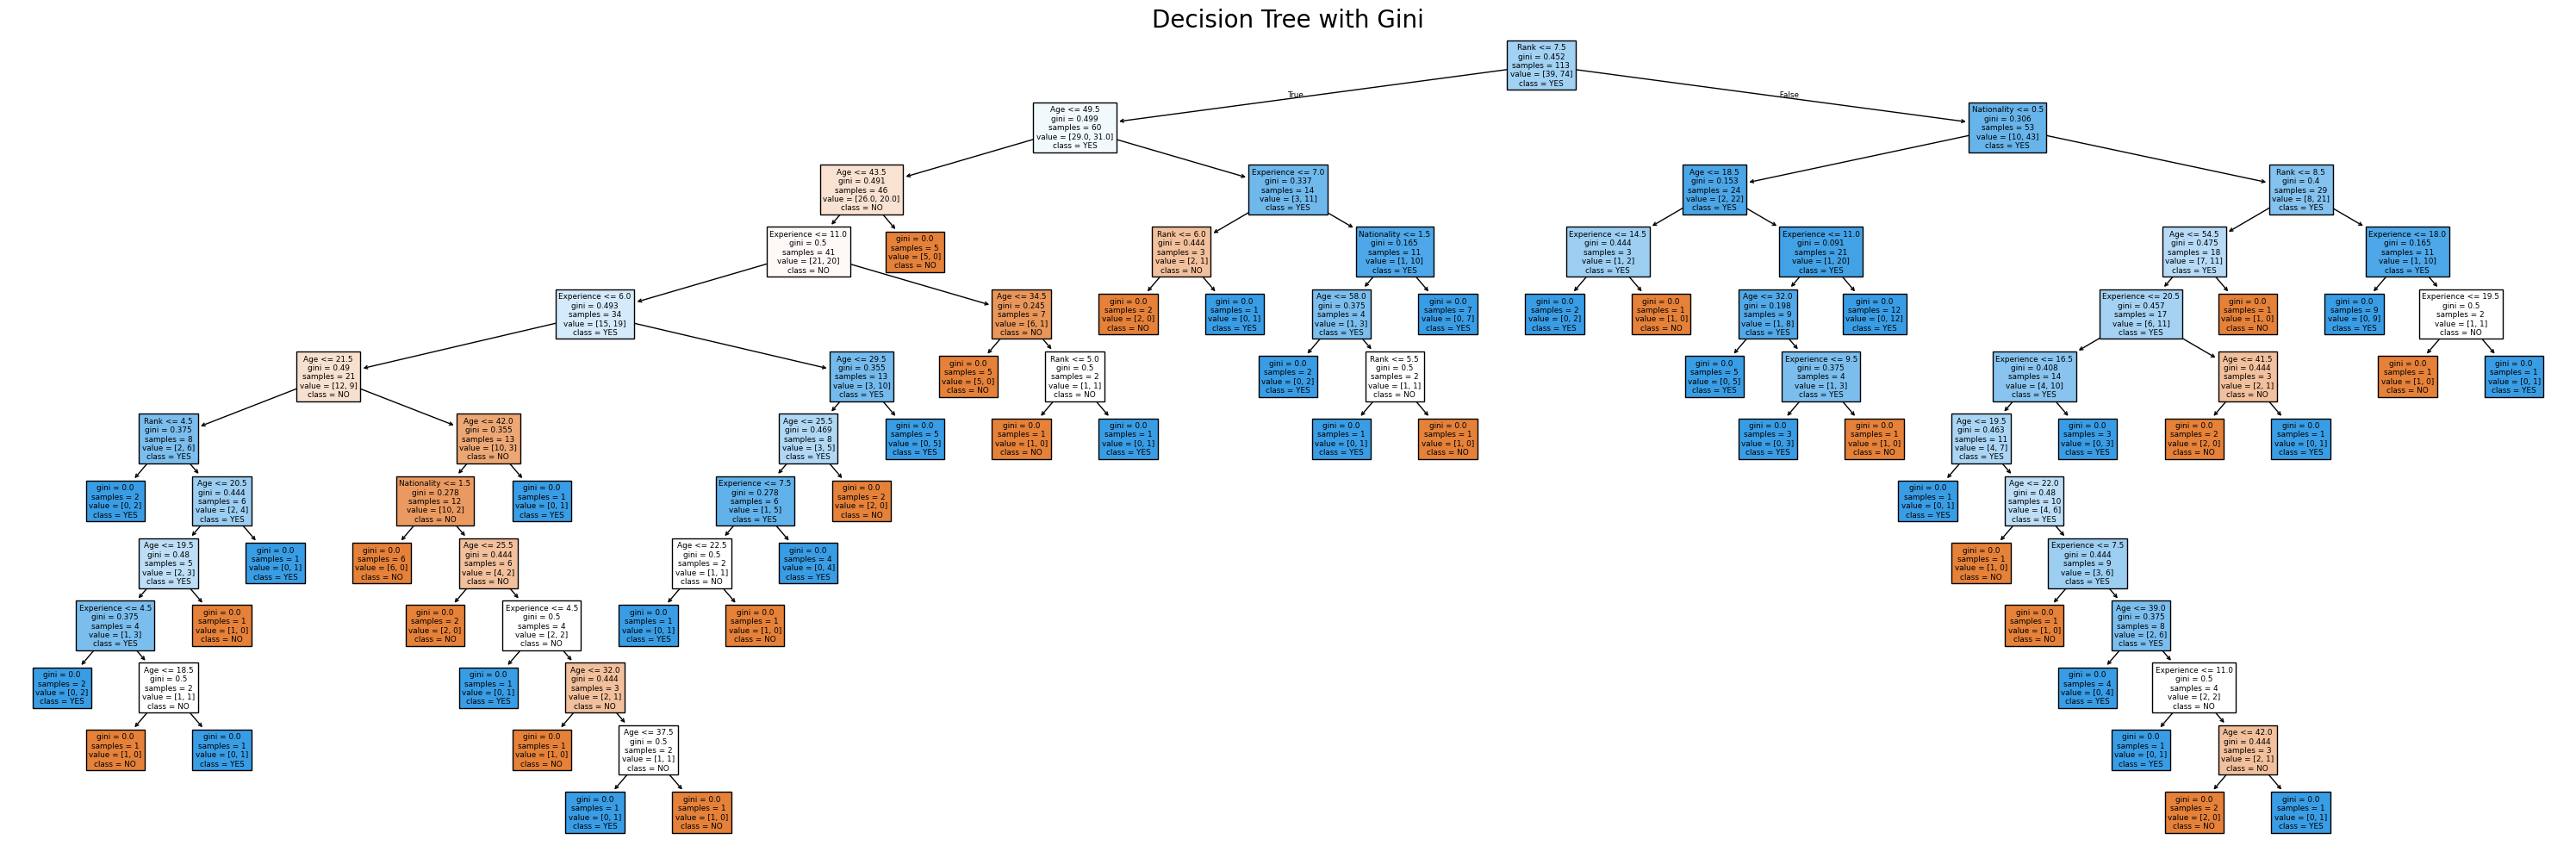

In [7]:
fig, ax = plt.subplots(figsize=(30, 10))

tree.plot_tree(
    gini_tree,
    feature_names=features,
    class_names=["NO", "YES"],
    filled=True,
    ax=ax,
)

ax.set_title("Decision Tree with Gini", fontsize=20)
plt.tight_layout()
plt.show()

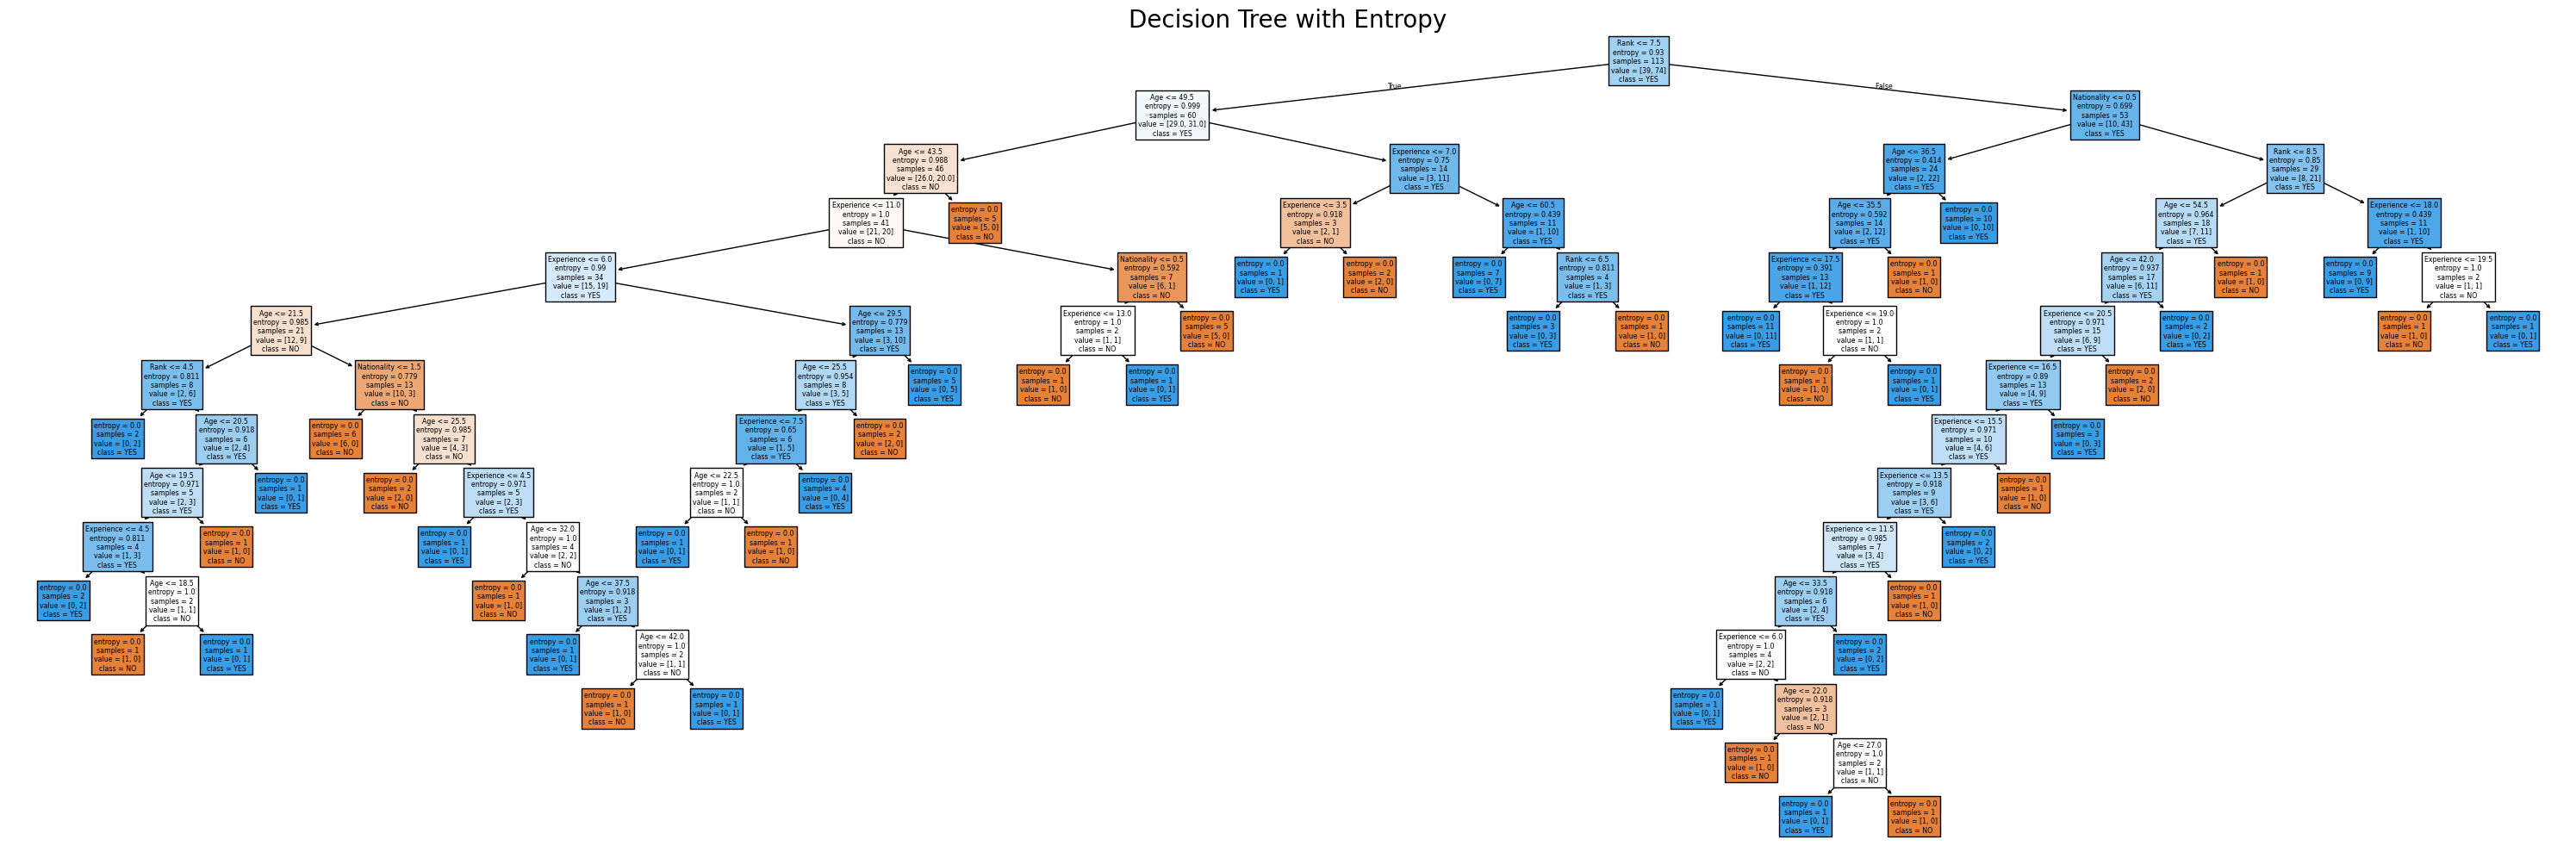

In [8]:
fig, ax = plt.subplots(figsize=(30, 10))

tree.plot_tree(
    entropy_tree,
    feature_names=features,
    class_names=["NO", "YES"],
    filled=True,
    ax=ax,
)

ax.set_title("Decision Tree with Entropy", fontsize=20)
plt.tight_layout()
plt.show()

#### Difrencess in feature importances

In [9]:
importance_comparison = pd.DataFrame({
    "Feature": features,
    "Gini importance": gini_tree.feature_importances_,
    "Entropy importance": entropy_tree.feature_importances_,
})
importance_comparison = importance_comparison.sort_values(
    "Gini importance", ascending=False
).reset_index(drop=True)
display(importance_comparison)

def top_feature(model):
    best_id = model.feature_importances_.argmax()
    return f"{features[best_id]} ({model.feature_importances_[best_id]:.3f})"

,Feature,Gini importance,Entropy importance
0,Age,0.475755,0.424271
1,Experience,0.294719,0.360775
2,Rank,0.191186,0.140385
3,Nationality,0.038340,0.074568


### What is the Gini method and how does it work?


Gini measures the impurity of each node in our tree. A Gini impurity of zero means that all samples belong to the same class. At each step, the tree selects the feature and threshold that produce the largest reduction in impurity.

### What are differences in the tree structure and feature importances between the model trained with Gini impurity and the model trained with entropy?

Generally, their output is so similar. But, Entropy is more sensitive to changes in the probabilities of rare classes, so it may sometimes select a different split.

The feature importances under Gini and Entropy, respectively, are 47.58% and 42.43% for `Age`, 29.47% and 36.08% for `Experience`, 19.12% and 14.04% for `Rank`, and 3.83% and 7.46% for `Nationality`.

Therefore, in this run, `Experience` and `Nationality` have higher relative importance in the Entropy-based model.

# 2. Boston house-prices

### A. Load and split the Boston dataset

ٔNote: Scikit-learn removed `load_boston` in version 1.2. So, I downloaded it from Kaggle. https://www.kaggle.com/datasets/vikrishnan/boston-house-prices

In [40]:
column_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']
boston_df = pd.read_csv('boston_housing.csv', names=column_names, delimiter=r"\s+")
boston_df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [41]:
X = boston_df.drop(["MEDV"], axis=1)
y = boston_df["MEDV"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, random_state=RANDOM_STATE, test_size=0.3
)

### B. Train a Random Forest regressors with n_estimators=100

In [42]:
rf_100 = RandomForestRegressor(
    n_estimators=100,
    random_state=RANDOM_STATE,
)

rf_100.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


### C. Evaluate the model

In [43]:
y_pred_100 = rf_100.predict(X_test)

mse = mean_squared_error(y_test, y_pred_100)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred_100)
mape = mean_absolute_percentage_error(y_test, y_pred_100) * 100
r2 = r2_score(y_test, y_pred_100)

metrics_table = pd.DataFrame({
    "Metric": ["MSE", "RMSE", "MAE", "MAPE", "R2"],
    "Value": [mse, rmse, mae, mape, r2],
})
display(metrics_table.round({"Value": 4}))

,Metric,Value
0,MSE,9.6197
1,RMSE,3.1016
2,MAE,2.0836
3,MAPE,10.8568
4,R2,0.8709


### D. Plot ground-truth vs predicted test values

Note: points closer to this the diagonal line have smaller prediction errors.

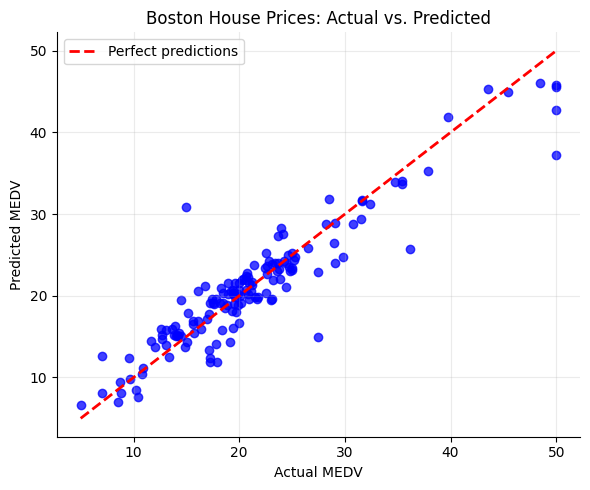

In [44]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_test, y_pred_100, alpha=0.75, color="blue")

line_min = min(y_test.min(), y_pred_100.min())
line_max = max(y_test.max(), y_pred_100.max())
ax.plot(
    [line_min, line_max],
    [line_min, line_max],
    linestyle="--",
    color="red",
    linewidth=2,
    label="Perfect predictions",
)

ax.set_title("Boston House Prices: Actual vs. Predicted")
ax.set_xlabel("Actual MEDV")
ax.set_ylabel("Predicted MEDV")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### E. Train regressors with n_estimators values of 50, 100, and 200

In [45]:
models = {}
for n_trees in (50, 100, 200):
    model = RandomForestRegressor(
        n_estimators=n_trees,
        random_state=RANDOM_STATE,
    )
    model.fit(X_train, y_train)
    models[n_trees] = model

comparison_rows = []
for n_trees in (50, 100, 200):
    predictions = models[n_trees].predict(X_test)
    comparison_rows.append({
        "Number of trees": n_trees,
        "Test RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "Test R2": r2_score(y_test, predictions),
    })

comparison_table = pd.DataFrame(comparison_rows)
comparison_table

,Number of trees,Test RMSE,Test R2
0,50,3.066819,0.873775
1,100,3.101558,0.870900
2,200,3.104518,0.870653


### F. Compare RMSE in dollars

`MEDV` is measured in thousands of dollars, so we multiply each test RMSE by 1,000 to show the error in U.S. dollars.

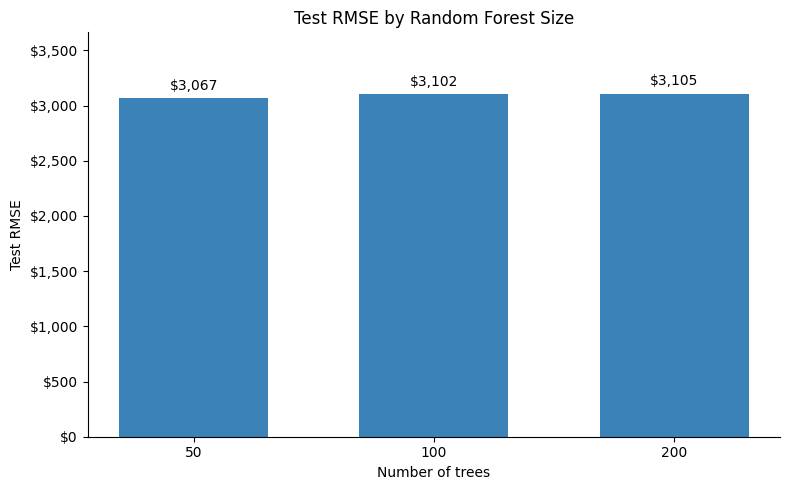

In [46]:
rmse_dollars = comparison_table["Test RMSE"].to_numpy() * 1000
n_trees_values = comparison_table["Number of trees"].to_numpy()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(n_trees_values.astype(str), rmse_dollars, color="#3b82b8", width=0.62)
ax.bar_label(bars, labels=[f"${value:,.0f}" for value in rmse_dollars], padding=4)
ax.set_title("Test RMSE by Random Forest Size")
ax.set_xlabel("Number of trees")
ax.set_ylabel("Test RMSE")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"${value:,.0f}"))
ax.set_ylim(0, max(rmse_dollars) * 1.18)
plt.tight_layout()
plt.show()

# 3. Titanic

### A. Load dataset

In [47]:
titanic_train_data = pd.read_csv('titanic_train.csv')
titanic_train_data['Sex'] = titanic_train_data['Sex'].map({'female': 0, 'male': 1})

titanic_features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare']
titanic_X = titanic_train_data[titanic_features]
titanic_y = titanic_train_data['Survived']

titanic_X_train, titanic_X_test, titanic_y_train, titanic_y_test = train_test_split(
    titanic_X, titanic_y, test_size=0.2, random_state=RANDOM_STATE)

### B. Fill missing ages using training rows only

In [48]:
titanic_age_median = titanic_X_train['Age'].median()
print(f'Median age of the training set: {titanic_age_median}')
titanic_X_train['Age'] = titanic_X_train['Age'].fillna(titanic_age_median)
titanic_X_test['Age'] = titanic_X_test['Age'].fillna(titanic_age_median)

Median age of the training set: 28.0


### C. Which features are most important?

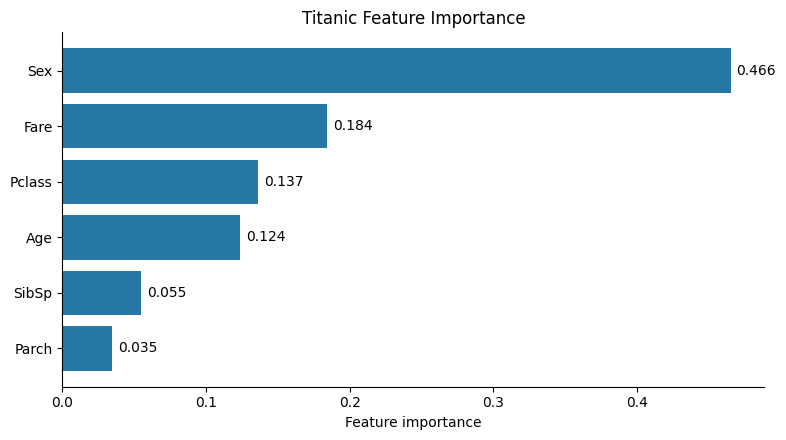

In [49]:
titanic_rf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=RANDOM_STATE)
titanic_rf.fit(titanic_X_train, titanic_y_train)

titanic_importance = pd.DataFrame({
    'Feature': titanic_features,
    'Importance': titanic_rf.feature_importances_,
}).sort_values('Importance', ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 4.5))
titanic_bars = ax.barh(
    titanic_importance['Feature'], titanic_importance['Importance'], color='#2878a5'
)
ax.invert_yaxis()
ax.bar_label(titanic_bars, fmt='%.3f', padding=4)
ax.set_xlabel('Feature importance')
ax.set_title('Titanic Feature Importance')
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

As we can see, `Fare`, `Sex`, and `Age` have the largest importance values.
These values describe the model's splits.They do not prove that a feature causes survival.

### D. Classification report and confusion matrix


Classification report:
                 precision    recall  f1-score   support

Did not survive      0.797     0.895     0.843       105
       Survived      0.820     0.676     0.741        74

       accuracy                          0.804       179
      macro avg      0.808     0.785     0.792       179
   weighted avg      0.806     0.804     0.801       179



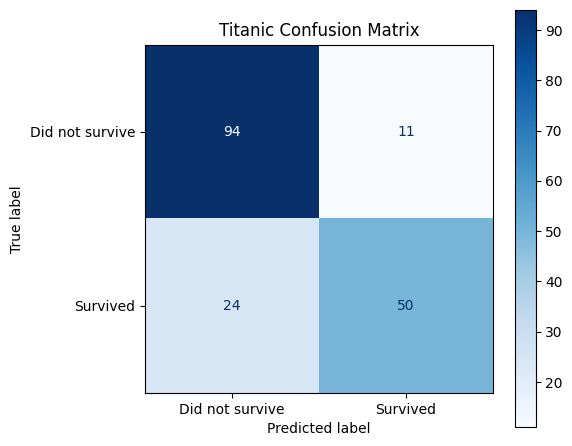

In [50]:
titanic_test_predictions = titanic_rf.predict(titanic_X_test)
class_names = ["Did not survive", "Survived"]

print("Classification report:")
print(
    classification_report(
        titanic_y_test,
        titanic_test_predictions,
        labels=[0, 1],
        target_names=class_names,
        digits=3,
        zero_division=0,
    )
)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    titanic_y_test,
    titanic_test_predictions,
    labels=[0, 1],
    display_labels=class_names,
    values_format="d",
    cmap="Blues",
    ax=ax,
)

ax.set_title("Titanic Confusion Matrix")
plt.tight_layout()
plt.show()

### E. Explain the false positives and false negatives

With survival as the positive class, a false positive is a passenger predicted to survive who actually did not survive. A false negative is a passenger predicted not to survive who actually survived. The “Did not survive” class has the higher recall compared with the “Survived” class. This means the model identifies a larger proportion of actual non-survivors than actual survivors.

### F. Train four models with max_depth values of 1, 2, 4, and 8

In [21]:
depth_values = [1, 2, 3, 4, 5, 8, 16, 32, 64]
titanic_depth_models = {}
results = []

importance_comparison = pd.DataFrame({
    "Feature": titanic_features
})

for depth in depth_values:
    model = RandomForestClassifier(
        max_depth=depth,
        n_estimators=100,
        random_state=RANDOM_STATE
    )
    model.fit(titanic_X_train, titanic_y_train)
    titanic_depth_models[depth] = model

    importance_comparison[f"Importance (depth={depth})"] = (
        model.feature_importances_
    )

    tree_depths = np.array([
        estimator.get_depth() for estimator in model.estimators_
    ])
    tree_leaves = np.array([
        estimator.get_n_leaves() for estimator in model.estimators_
    ])

    results.append({
        "Maximum depth setting": depth,
        "Maximum actual tree depth": tree_depths.max(),
        "Mean actual tree depth": round(tree_depths.mean(), 2),
        "Total leaves in forest": tree_leaves.sum(),
        "Mean leaves per tree": round(tree_leaves.mean(), 2),
        "Training accuracy": model.score(titanic_X_train, titanic_y_train),
        "Test accuracy": model.score(titanic_X_test, titanic_y_test),
    })

depth_comparison = pd.DataFrame(results)
depth_comparison[["Training accuracy", "Test accuracy"]] = (
    depth_comparison[["Training accuracy", "Test accuracy"]].round(3)
)
display(depth_comparison)

importance_comparison = importance_comparison.sort_values(
    by="Importance (depth=5)",
    ascending=False,
).reset_index(drop=True)

display(importance_comparison.round(3))

,Maximum depth setting,Maximum actual tree depth,Mean actual tree depth,Total leaves in forest,Mean leaves per tree,Training accuracy,Test accuracy
0,1,1,1.00,200,2.00,0.795,0.777
1,2,2,2.00,400,4.00,0.799,0.760
2,3,3,3.00,778,7.78,0.836,0.777
3,4,4,4.00,1423,14.23,0.855,0.793
4,5,5,5.00,2309,23.09,0.858,0.804
5,8,8,8.00,6317,63.17,0.906,0.799
6,16,16,15.94,13742,137.42,0.979,0.799
7,32,25,18.24,14282,142.82,0.979,0.799
8,64,25,18.24,14282,142.82,0.979,0.799


,Feature,Importance (depth=1),Importance (depth=2),Importance (depth=3),Importance (depth=4),Importance (depth=5),Importance (depth=8),Importance (depth=16),Importance (depth=32),Importance (depth=64)
0,Sex,0.32,0.473,0.498,0.468,0.466,0.375,0.275,0.271,0.271
1,Fare,0.25,0.190,0.171,0.195,0.184,0.230,0.303,0.305,0.305
2,Pclass,0.22,0.194,0.168,0.148,0.137,0.110,0.080,0.078,0.078
3,Age,0.07,0.069,0.075,0.101,0.124,0.179,0.256,0.260,0.260
4,SibSp,0.04,0.039,0.059,0.053,0.055,0.060,0.049,0.050,0.050
5,Parch,0.10,0.036,0.029,0.035,0.035,0.045,0.038,0.037,0.037


You can see that increasing max_depth makes the model overfit.

### F. Kaggle report

In [22]:
submission_test = pd.read_csv('titanic_test.csv')
submission_test['Sex'] = submission_test['Sex'].map({'female': 0, 'male': 1})
submission_test['Age'] = submission_test['Age'].fillna(titanic_age_median)
submission_X_test = submission_test[titanic_features]

In [23]:
submission_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=RANDOM_STATE,
)
submission_model.fit(titanic_X_train, titanic_y_train)

submission = pd.DataFrame({
    "PassengerId": submission_test["PassengerId"],
    "Survived": submission_model.predict(submission_X_test),
})

submission.to_csv("kaggle_submission.csv", index=False)

You can find my result here: https://www.kaggle.com/competitions/titanic/leaderboard?search=mehrdad

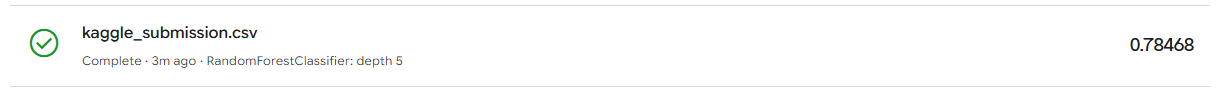

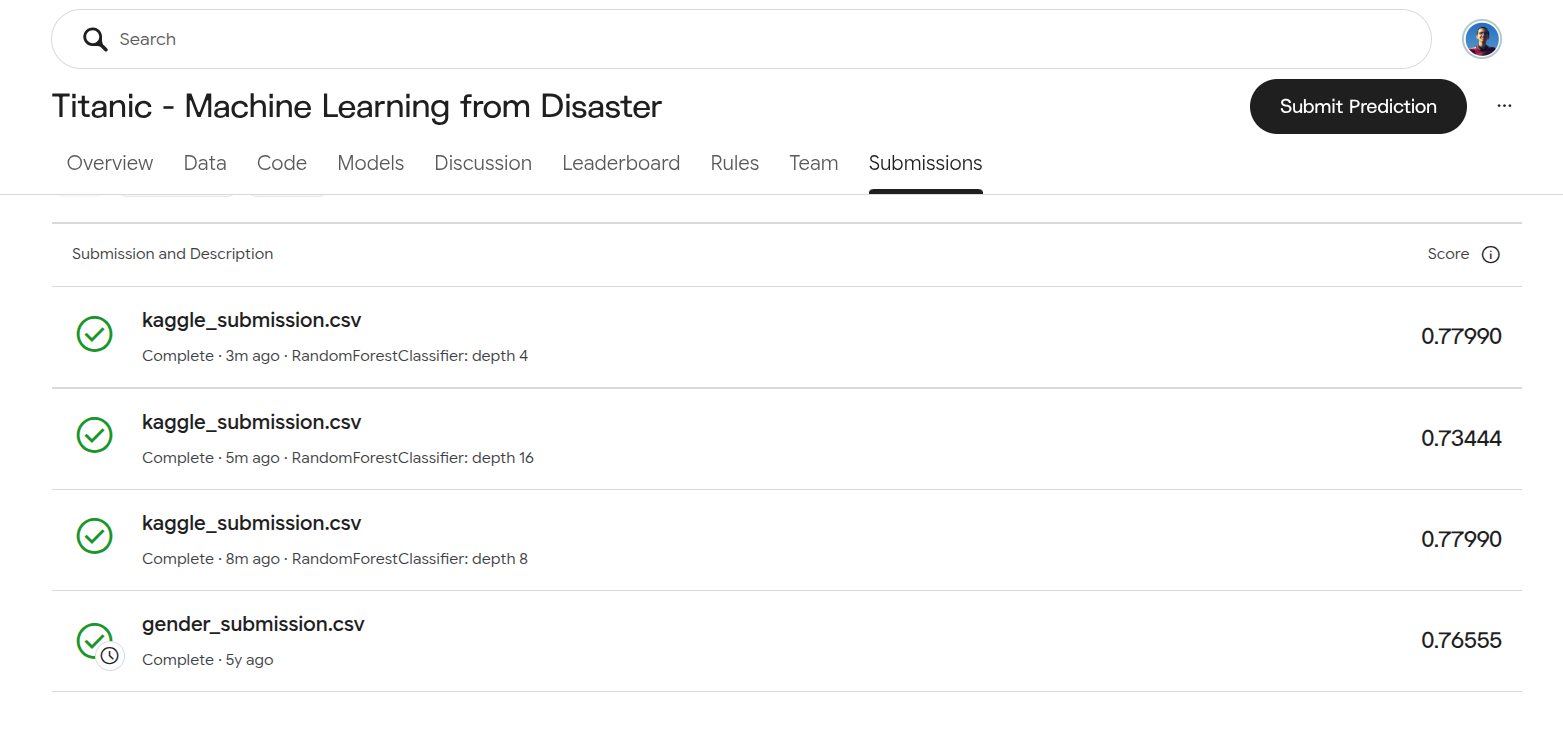

# 4. Give Me Some Credit

In [ ]:
credits_train = pd.read_csv('credit_train.csv')
credits_test = pd.read_csv('credit_test.csv')
credits_train.head()

,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,SeriousDlqin,MonthlyIncome_missing,Is_Outlier,TotalPastDue,Has90DaysLate,WorstDelayStatus
0,0.203223,60,1,2,0,1600.000000,5416.0,8,0,1,0,0.0,0,1,True,0,0,0
1,1.000000,24,0,3,0,0.100074,1358.0,3,0,0,0,0.0,0,0,False,0,0,0
2,0.200152,49,0,1,0,0.224416,12917.0,8,0,1,0,0.0,0,0,True,0,0,0
3,0.025735,78,1,1,0,347.000000,5416.0,7,0,0,0,0.0,0,1,True,0,0,0
4,0.133169,29,0,3,0,723.000000,5416.0,5,0,0,0,0.0,0,1,True,0,0,0


In [25]:
credits_X_train = credits_train.drop(columns=['SeriousDlqin', "Is_Outlier"])
credits_y_train = credits_train['SeriousDlqin']

credits_X_test = credits_test.drop(columns=['SeriousDlqin'])
credits_y_test = credits_test['SeriousDlqin']

### A. Baseline

`SeriousDlqin = 1` (delinquency) is the positive class. This baseline Random Forest is fitted on `credits_train` and evaluated on the `credits_test` data.

Classification report:
                    precision    recall  f1-score   support

No delinquency (0)     0.9454    0.9890    0.9667     41950
   Delinquency (1)     0.5509    0.1917    0.2844      2963

          accuracy                         0.9364     44913
         macro avg     0.7482    0.5903    0.6256     44913
      weighted avg     0.9194    0.9364    0.9217     44913



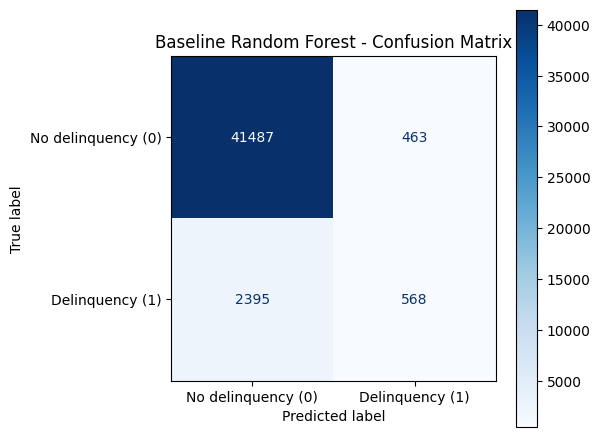

In [26]:
baseline_credits_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
)
baseline_credits_rf.fit(credits_X_train, credits_y_train)
baseline_credits_rf_y_pred = baseline_credits_rf.predict(credits_X_test)

print("Classification report:")
print(
    classification_report(
        credits_y_test,
        baseline_credits_rf_y_pred,
        labels=[0, 1],
        target_names=["No delinquency (0)", "Delinquency (1)"],
        digits=4,
    )
)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    credits_y_test,
    baseline_credits_rf_y_pred,
    labels=[0, 1],
    display_labels=["No delinquency (0)", "Delinquency (1)"],
    values_format="d",
    cmap="Blues",
    ax=ax,
)
ax.set_title("Baseline Random Forest - Confusion Matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
fig.tight_layout()
plt.show()

**Why accuracy alone is misleading?** 

About 93.4% of the labeled rows are non-delinquent, so a model that predicts class 0 for every person would already score about 93.4% accuracy. This baseline reaches about 93.6%, but its recall for delinquency is only about 19.17%. Therefore, precision, recall, and F1 for class 1 matter alongside accuracy.

### B. RandomForestClassifier + SMOTENC

`SMOTENC` augment the minority-class examples from the training data.

In [27]:
from imblearn.over_sampling import SMOTENC

categorical = [
    "SEX", "EDUCATION", "Has90DaysLate",
    "WorstDelayStatus", "MonthlyIncome_missing"
]

smotenc = SMOTENC(
    categorical_features=categorical,
    sampling_strategy=1,
    random_state=RANDOM_STATE
)

augmented_X_train, augmented_y_train = smotenc.fit_resample(credits_X_train, credits_y_train)
SMOTENC_rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
SMOTENC_rf.fit(augmented_X_train, augmented_y_train)
SMOTENC_y_pred = SMOTENC_rf.predict(credits_X_test)

print("Classification report:")
print(
    classification_report(
        credits_y_test,
        SMOTENC_y_pred,
        labels=[0, 1],
        target_names=["No delinquency (0)", "Delinquency (1)"],
        digits=4,
    )
)

Classification report:
                    precision    recall  f1-score   support

No delinquency (0)     0.9534    0.9647    0.9590     41950
   Delinquency (1)     0.3999    0.3331    0.3635      2963

          accuracy                         0.9230     44913
         macro avg     0.6767    0.6489    0.6613     44913
      weighted avg     0.9169    0.9230    0.9197     44913



### D. Compare feature relationships before and after SMOTENC

As we can see, after applying SMOTENC on our training dataset, distribution of the features have changed a little bit. But it is not a big deal!

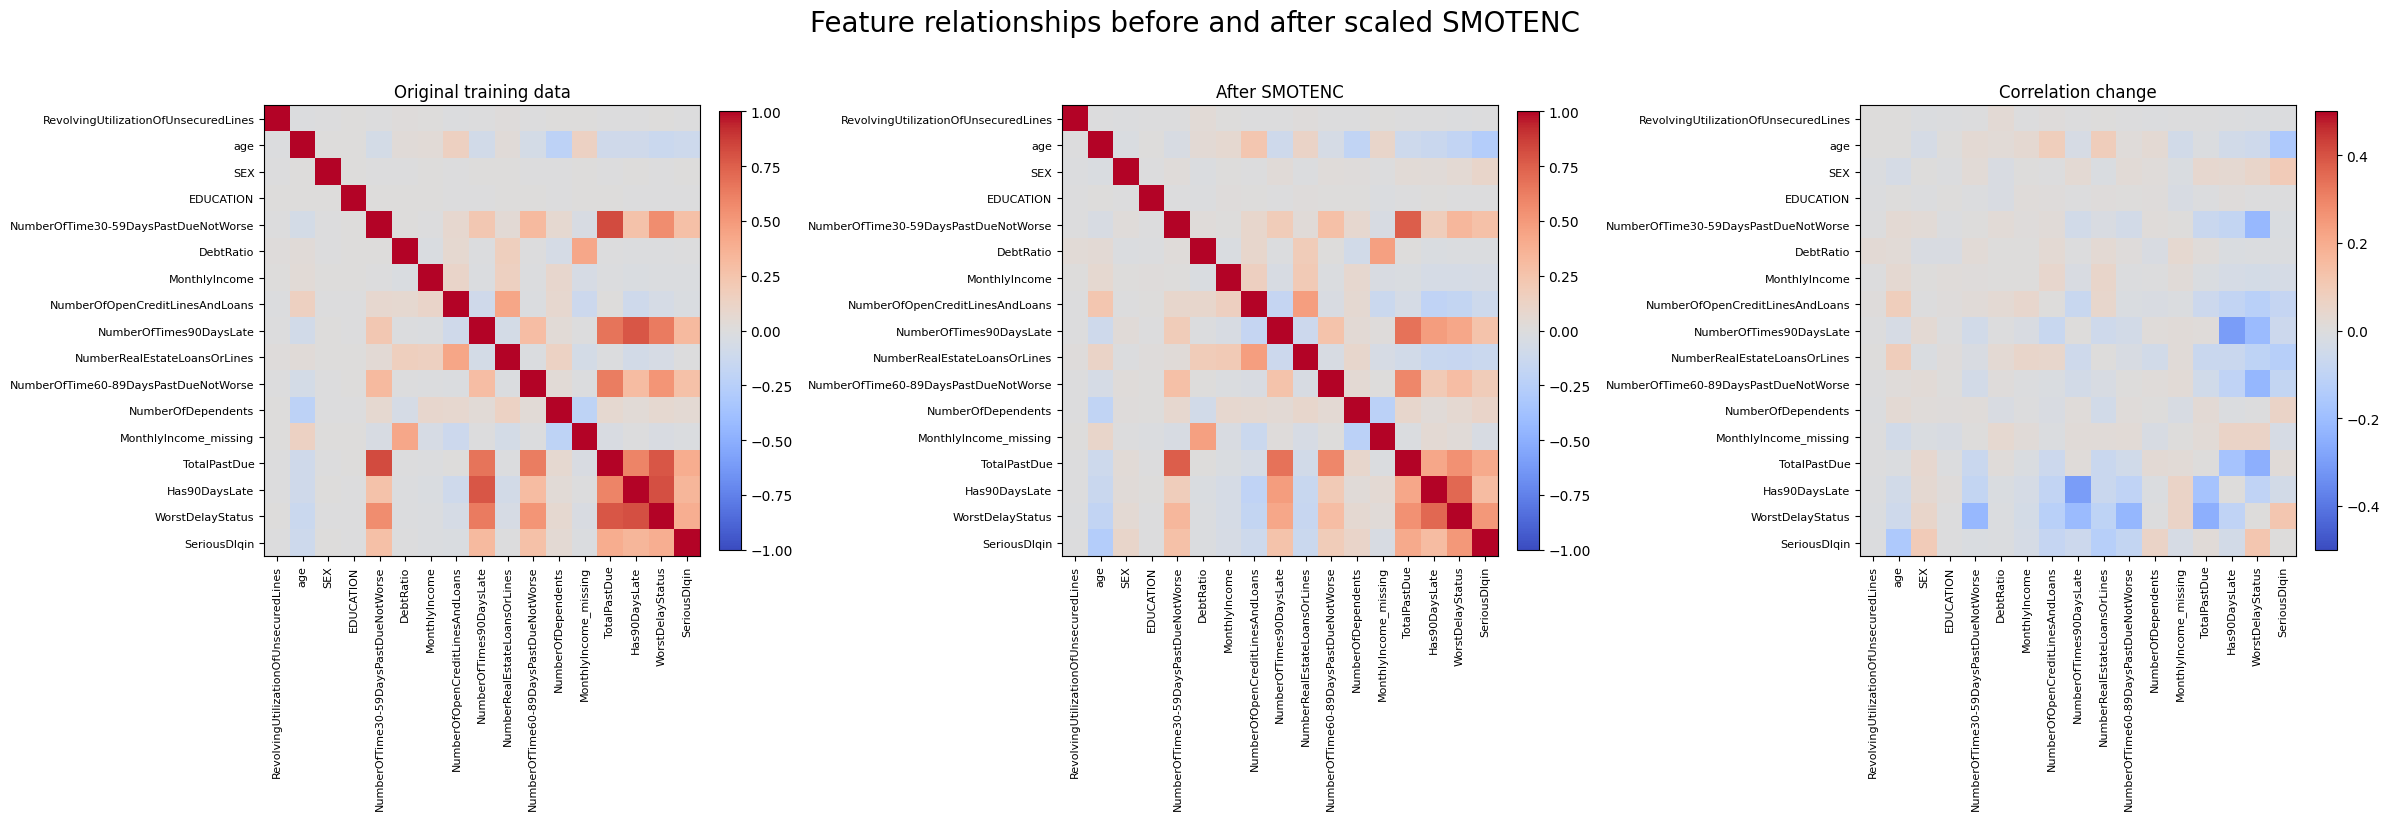

In [28]:
original_corr_data = credits_X_train.reset_index(drop=True).copy()
original_corr_data["SeriousDlqin"] = credits_y_train.reset_index(drop=True)
augmented_corr_data = augmented_X_train.reset_index(drop=True).copy()
augmented_corr_data["SeriousDlqin"] = augmented_y_train.reset_index(drop=True)

corr_before = original_corr_data.corr(method="pearson")
corr_after = augmented_corr_data.corr(method="pearson")
corr_change = corr_after - corr_before

fig, axes = plt.subplots(1, 3, figsize=(24, 8))
heatmap_settings = [
    (corr_before, "Original training data", -1, 1),
    (corr_after, "After SMOTENC", -1, 1),
    (corr_change, "Correlation change", -0.5, 0.5),
]
for ax, (matrix, title, vmin, vmax) in zip(axes, heatmap_settings):
    image = ax.imshow(matrix, cmap="coolwarm", vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_title(title)
    ax.set_xticks(range(len(matrix.columns)))
    ax.set_xticklabels(matrix.columns, rotation=90, fontsize=8)
    ax.set_yticks(range(len(matrix.index)))
    ax.set_yticklabels(matrix.index, fontsize=8)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.suptitle("Feature relationships before and after scaled SMOTENC", y=1.02, fontsize=20)
fig.tight_layout()
plt.show()

### E. Remove outliers from the augmented train set
I have used three methods of 1) IQR based, 2) Isolation Forest, and IQR +Isolation Forest for outlier detection, and I got the best Recall for the "Delinquency" class with the IQR based outlier detection.


- Note: IQR + Isolation Forest means we only remove those values that both methods identified them as outlier. 
- Note: In this assigment, higher recall for the Delinquency class is more important.

In [29]:
# 1. IQR outlier detection
continuous_features = [
    "RevolvingUtilizationOfUnsecuredLines",
    "age",
    "DebtRatio",
    "MonthlyIncome",
]

q1 = augmented_X_train[continuous_features].quantile(0.25)
q3 = augmented_X_train[continuous_features].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

iqr_outlier_mask = (
    (augmented_X_train[continuous_features] < lower_bound)
    | (augmented_X_train[continuous_features] > upper_bound)
).any(axis=1)

# 2. Isolation Forest outlier detection
isolation_forest = IsolationForest(
    n_estimators=200,
    contamination=0.01,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

isolation_outlier_mask = (
    isolation_forest.fit_predict(augmented_X_train) == -1
)

# 3. Define the three removal strategies
outlier_methods = {
    "IQR": iqr_outlier_mask,
    "Isolation Forest": isolation_outlier_mask,
    "IQR + Isolation Forest (common)": (
        iqr_outlier_mask & isolation_outlier_mask
    ),
}

# 4. Train and evaluate one model per strategy
results = []

for method_name, outlier_mask in outlier_methods.items():

    X_train_clean = augmented_X_train.loc[~outlier_mask].copy()
    y_train_clean = augmented_y_train.loc[~outlier_mask].copy()

    model = RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE,
    )

    model.fit(X_train_clean, y_train_clean)
    predictions = model.predict(credits_X_test)

    results.append({
        "Method": method_name,
        "Outliers removed": outlier_mask.sum(),
        "Train rows after removal": len(X_train_clean),
        "Accuracy": accuracy_score(credits_y_test, predictions),
        "Precision (Delinquency)": precision_score(
            credits_y_test, predictions,
            pos_label=1,
            average="binary",
        ),
        "Recall (Delinquency)": recall_score(
            credits_y_test, predictions,
            pos_label=1,
            average="binary",
        ),
        "F1-score (Delinquency)": f1_score(
            credits_y_test, predictions,
            pos_label=1,
            average="binary",
        ),
    })

comparison_results = pd.DataFrame(results)

display(
    comparison_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision (Delinquency)": "{:.4f}",
        "Recall (Delinquency)": "{:.4f}",
        "F1-score (Delinquency)": "{:.4f}",
    })
)

,Method,Outliers removed,Train rows after removal,Accuracy,Precision (Delinquency),Recall (Delinquency),F1-score (Delinquency)
0,IQR,51652,144112,0.9120,0.3353,0.3402,0.3377
1,Isolation Forest,1958,193806,0.9224,0.3935,0.3260,0.3566
2,IQR + Isolation Forest (common),1307,194457,0.9229,0.3989,0.3341,0.3636


### F. Change classifier model
Here I have compared five classifiers across five training-data settings.

In [ ]:
continuous_features = [
    "RevolvingUtilizationOfUnsecuredLines", "age", "DebtRatio", "MonthlyIncome"]

def remove_iqr_outliers(X, y):
    q1, q3 = X[continuous_features].quantile(
        0.25), X[continuous_features].quantile(0.75)
    iqr = q3 - q1
    outlier_mask = ((X[continuous_features] < q1 - 1.5 * iqr) |
                    (X[continuous_features] > q3 + 1.5 * iqr)).any(axis=1)
    return X.loc[~outlier_mask].copy(), y.loc[~outlier_mask].copy(), int(outlier_mask.sum())

# SMOTENC is fitted only on the training split.
smote_for_comparison = SMOTENC(
    categorical_features=categorical, sampling_strategy=1, random_state=RANDOM_STATE)
X_train_augmented, y_train_augmented = smote_for_comparison.fit_resample(
    credits_X_train, credits_y_train)
X_train_iqr, y_train_iqr, removed_iqr_raw = remove_iqr_outliers(
    credits_X_train, credits_y_train)
X_train_augmented_iqr, y_train_augmented_iqr, removed_iqr_augmented = remove_iqr_outliers(
    X_train_augmented, y_train_augmented)

data_settings = {
    "Normal / no augmentation": (credits_X_train, credits_y_train, 0, False),
    "Normal / no augmentation + class-weighted": (credits_X_train, credits_y_train, 0, True),
    "Normal / with SMOTENC augmentation": (X_train_augmented, y_train_augmented, 0, False),
    "IQR / no augmentation": (X_train_iqr, y_train_iqr, removed_iqr_raw, False),
    "IQR / with SMOTENC augmentation": (X_train_augmented_iqr, y_train_augmented_iqr, removed_iqr_augmented, False),
}

def make_model(model_name, class_weighted, y_fit):
    if model_name == "Decision Tree":
        return DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced" if class_weighted else None), None
    if model_name == "XGBoost":
        pos_weight = (y_fit == 0).sum() / \
            (y_fit == 1).sum() if class_weighted else 1
        return XGBClassifier(n_estimators=250, max_depth=6, learning_rate=0.08, subsample=0.8,
                             colsample_bytree=0.8, scale_pos_weight=pos_weight, eval_metric="logloss",
                             tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE), None
    if model_name == "Logistic Regression":
        return LogisticRegression(max_iter=10000, random_state=RANDOM_STATE,
                                  class_weight="balanced" if class_weighted else None), None
    if model_name == "SVM (LinearSVC)":
        model = LinearSVC(
            C=1.0,
            class_weight="balanced" if class_weighted else None,
            dual=False,
            max_iter=10000,
            random_state=RANDOM_STATE,
        )
        return model, None
    model = GradientBoostingClassifier(
        n_estimators=50, learning_rate=0.08, max_depth=3, random_state=RANDOM_STATE)
    weights = compute_sample_weight(
        "balanced", y_fit) if class_weighted else None
    return model, weights


model_names = ["Decision Tree", "XGBoost", "Logistic Regression",
               "Gradient Boosting", "SVM (LinearSVC)"]
comparison_rows = []
for setting_name, (X_fit, y_fit, outliers_removed, class_weighted) in data_settings.items():
    for model_name in model_names:
        model, sample_weight = make_model(model_name, class_weighted, y_fit)
        if model_name in ("Logistic Regression", "SVM (LinearSVC)"):
            scaler = RobustScaler()
            X_fit_model, X_test_model = scaler.fit_transform(
                X_fit), scaler.transform(credits_X_test)
        else:
            X_fit_model, X_test_model = X_fit, credits_X_test
        fit_kwargs = {} if sample_weight is None else {"sample_weight": sample_weight}
        model.fit(X_fit_model, y_fit, **fit_kwargs)
        y_pred = model.predict(X_test_model)
        if hasattr(model, "predict_proba"):
            y_score = model.predict_proba(X_test_model)[:, 1]
        else:
            y_score = model.decision_function(X_test_model)
        pr_precision, pr_recall, _ = precision_recall_curve(
            credits_y_test, y_score)
        comparison_rows.append({
            "Model": model_name, "Data setting": setting_name,
            "Accuracy": accuracy_score(credits_y_test, y_pred),
            "Precision (Delinquency)": precision_score(credits_y_test, y_pred, 
                                                    pos_label=1, average="binary",),
            "Recall (Delinquency)": recall_score(credits_y_test, y_pred,
                                                pos_label=1, average="binary",),
            "F1-score (Delinquency)": f1_score(credits_y_test, y_pred, 
                                               pos_label=1, average="binary",),
            "ROC-AUC": roc_auc_score(credits_y_test, y_score),
            "PR-AUC": auc(pr_recall, pr_precision),
        })

model_comparison = pd.DataFrame(comparison_rows)
display(model_comparison.style.format({
    "Accuracy": "{:.4f}", "Precision (Delinquency)": "{:.4f}",
    "Recall (Delinquency)": "{:.4f}", "F1-score (Delinquency)": "{:.4f}",
    "ROC-AUC": "{:.4f}",
    "PR-AUC": "{:.4f}",
}))

,Model,Data setting,Accuracy,Precision (Delinquency),Recall (Delinquency),F1-score (Delinquency),ROC-AUC,PR-AUC
0,Decision Tree,Normal / no augmentation,0.8944,0.2360,0.2686,0.2513,0.6038,0.2765
1,XGBoost,Normal / no augmentation,0.9370,0.5671,0.1910,0.2858,0.8542,0.3704
2,Logistic Regression,Normal / no augmentation,0.9370,0.5936,0.1444,0.2324,0.8096,0.3384
3,Gradient Boosting,Normal / no augmentation,0.9379,0.6043,0.1691,0.2642,0.8511,0.3798
4,SVM (LinearSVC),Normal / no augmentation,0.9371,0.6254,0.1178,0.1982,0.8095,0.3435
5,Decision Tree,Normal / no augmentation + class-weighted,0.9031,0.2540,0.2423,0.2480,0.5960,0.2730
6,XGBoost,Normal / no augmentation + class-weighted,0.8220,0.2283,0.7135,0.3459,0.8516,0.3670
7,Logistic Regression,Normal / no augmentation + class-weighted,0.8319,0.2269,0.6426,0.3353,0.8105,0.3369
8,Gradient Boosting,Normal / no augmentation + class-weighted,0.7791,0.1985,0.7732,0.3160,0.8527,0.3760
9,SVM (LinearSVC),Normal / no augmentation + class-weighted,0.8278,0.2223,0.6443,0.3305,0.8094,0.3203


Choosing the best model is really depends on the bussiness mindset. Here, I mention two choices that make senses.


**Gradient Boosting + IQR + SMOTENC augmentation**: F1: 0.3883, Recall: 0.5710, Precision: 0.2942

This model provides a better balance between detecting defaults and making accurate alerts.


**Gradient Boosting	+ no augmentation + class-weighted**: F1: 0.3160, Recall: 0.7732, Precision: 0.1985	

If missing a default is more costly and you prioritize recall, this model has the highest recall. However, its precision is low, so it produces more false alarms.


### G. Hyperparameter tuning

I have used "RandomizedSearchCV" to find the best hyperparameters for the Gradient Boosting (IQR + SMOTENC augmentation) which is the best model in terms of being balanced between detecting defaults and making accurate alerts.

Here is the final results of "RandomizedSearchCV":

In [31]:
# {'gb__learning_rate': 0.0830947290430651, 'gb__max_depth': 3,
#  'gb__max_features': 0.8, 'gb__min_samples_leaf': 37,
#  'gb__min_samples_split': 28, 'gb__n_estimators': 54,
#  'gb__subsample': 0.9742053074796722}

tuned_model = GradientBoostingClassifier(
    n_estimators=54,
    learning_rate=0.0830947290430651,
    max_depth=3,
    max_features=8,
    min_samples_split=28,
    min_samples_leaf=37,
    subsample=0.9742053074796722,
    random_state=RANDOM_STATE,
)

tuned_model.fit(X_train_augmented_iqr, y_train_augmented_iqr)
y_pred = tuned_model.predict(credits_X_test)
print(classification_report(
    credits_y_test,
    y_pred,
    labels=[0, 1],
    target_names=["No delinquency (0)", "Delinquency (1)"],
    digits=4,
))

                    precision    recall  f1-score   support

No delinquency (0)     0.9689    0.8957    0.9309     41950
   Delinquency (1)     0.2863    0.5923    0.3861      2963

          accuracy                         0.8757     44913
         macro avg     0.6276    0.7440    0.6585     44913
      weighted avg     0.9238    0.8757    0.8949     44913



# 5. Women vs Men

### A. Load dataset

In [32]:
male_data = pd.read_csv("ANSUR II MALE Public.csv", encoding="latin1")
female_data = pd.read_csv("ANSUR II FEMALE Public.csv", encoding="latin1")

male_data.columns = male_data.columns.str.strip().str.lower()
female_data.columns = female_data.columns.str.strip().str.lower()

ansur_data = pd.concat([male_data, female_data], ignore_index=True)
ansur_data.head()

,subjectid,abdominalextensiondepthsitting,acromialheight,acromionradialelength,anklecircumference,axillaheight,balloffootcircumference,balloffootlength,biacromialbreadth,bicepscircumferenceflexed,...,branch,primarymos,subjectsbirthlocation,subjectnumericrace,ethnicity,dodrace,age,heightin,weightlbs,writingpreference
0,10027,266,1467,337,222,1347,253,202,401,369,...,Combat Arms,19D,North Dakota,1,NaN,1,41,71,180,Right hand
1,10032,233,1395,326,220,1293,245,193,394,338,...,Combat Support,68W,New York,1,NaN,1,35,68,160,Left hand
2,10033,287,1430,341,230,1327,256,196,427,408,...,Combat Support,68W,New York,2,NaN,2,42,68,205,Left hand
3,10092,234,1347,310,230,1239,262,199,401,359,...,Combat Service Support,88M,Wisconsin,1,NaN,1,31,66,175,Right hand
4,10093,250,1585,372,247,1478,267,224,435,356,...,Combat Service Support,92G,North Carolina,2,NaN,2,21,77,213,Right hand


### B. Preprocess and clean the dataset

In [33]:
ansur_data["gender"] = ansur_data["gender"].str.strip().str.title()
ansur_data = ansur_data[ansur_data["gender"].isin(["Female", "Male"])].drop_duplicates().copy()

columns_to_exclude = [
    "subjectid", "gender", "subjectnumericrace", "dodrace",
    "age", "heightin", "weightlbs", "date", "installation"
]

X_ansur = ansur_data.drop(columns=columns_to_exclude, errors="ignore")
X_ansur = X_ansur.select_dtypes(include="number").copy()
X_ansur = X_ansur.fillna(X_ansur.median())
y_ansur = ansur_data["gender"]

print(f"Rows after cleaning: {len(ansur_data):,}")
print(f"Numeric body-measurement features: {X_ansur.shape[1]}")
print(f"Missing feature values after cleaning: {X_ansur.isna().sum().sum()}")
print("Rows by gender:")
print(y_ansur.value_counts())

Rows after cleaning: 6,068
Numeric body-measurement features: 93
Missing feature values after cleaning: 0
Rows by gender:
gender
Male      4082
Female    1986
Name: count, dtype: int64


### C. Plot the heights for women and men

The `stature` measurements are stored in millimeters, so the plot converts them to centimeters. Density is used so the two groups can be compared fairly despite having different numbers of participants.

**Why is the men's data higher than the women's data?**

It actually make sense! Because in most countries there are more male soldiers than female soldiers. For more information see this link: https://usafacts.org/articles/how-many-people-are-in-the-us-military-a-demographic-overview/

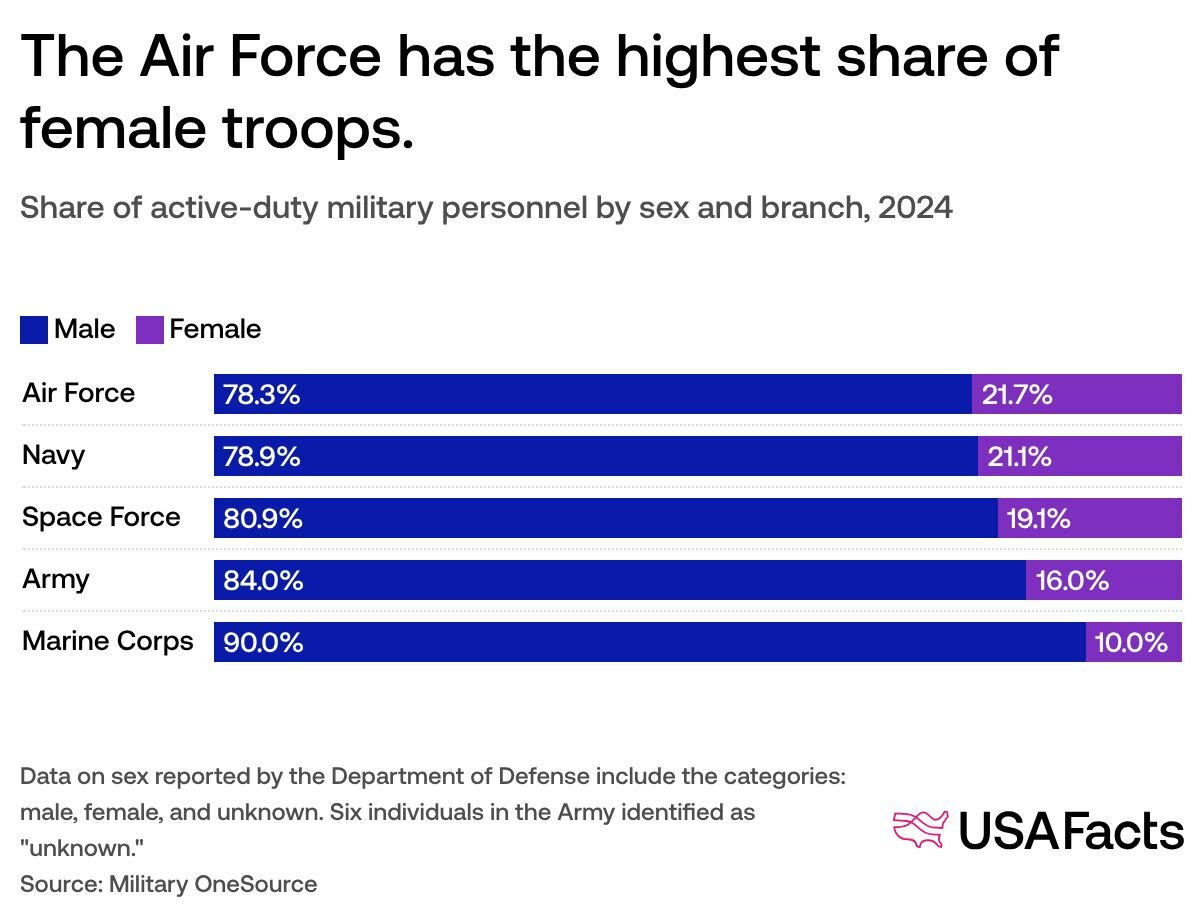

**Why is the men's data more right than the women's data?**

Men's heights are shifted to the right because adult men are typically taller on average, and this sample shows that pattern (about 175.6 cm for men and 162.9 cm for women). The men's distribution reaches farther right because this sample includes taller men (up to about 199.3 cm, compared with 182.9 cm for women), although the two groups still overlap.

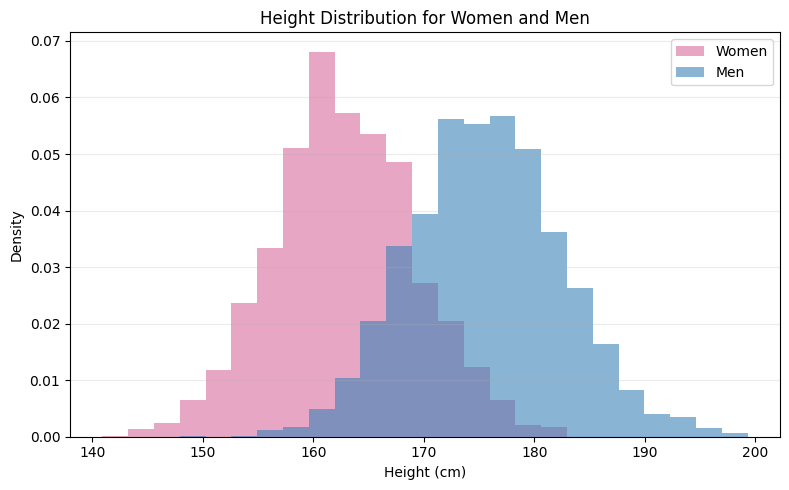

In [34]:
female_heights = ansur_data.loc[ansur_data["gender"] == "Female", "stature"] / 10
male_heights = ansur_data.loc[ansur_data["gender"] == "Male", "stature"] / 10
height_bins = np.linspace(ansur_data["stature"].min() / 10,
                          ansur_data["stature"].max() / 10, 26)

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(female_heights, bins=height_bins, density=True, alpha=0.6,
        color="#d86b9b", label="Women")
ax.hist(male_heights, bins=height_bins, density=True, alpha=0.6,
        color="#3b82b8", label="Men")
ax.set_title("Height Distribution for Women and Men")
ax.set_xlabel("Height (cm)")
ax.set_ylabel("Density")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### D. Split the dataset into training and test sets

The test set contains 20% of the rows. Stratification keeps the female and male proportions similar in both sets.

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X_ansur, y_ansur, test_size=0.20, random_state=RANDOM_STATE, stratify=y_ansur
)

### E. Train a Decision Tree and a Bagging classifier

Bagging trains many Decision Trees on bootstrap samples of the training data and combines their predictions. The table compares the original Decision Tree with the bagged model on the same test set.

In [36]:
# Decision Tree model as the baseline
decision_tree_model = DecisionTreeClassifier(random_state=RANDOM_STATE)
decision_tree_model.fit(X_train, y_train)

# Bagging
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    n_estimators=100,
    random_state=RANDOM_STATE,
)
bagging_model.fit(X_train, y_train)

positive_class = "Male"
model_rows = []
for model_name, model in [
    ("Decision Tree", decision_tree_model),
    ("Bagging with Decision Trees", bagging_model),
]:
    predictions = model.predict(X_test)
    male_column = list(model.classes_).index(positive_class)
    male_probabilities = model.predict_proba(X_test)[:, male_column]

    model_rows.append({
        "Model": model_name,
        "Recall": recall_score(y_test, predictions, pos_label=positive_class),
        "Precision": precision_score(y_test, predictions, pos_label=positive_class),
        "F1": f1_score(y_test, predictions, pos_label=positive_class),
        "Accuracy": accuracy_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test == positive_class, male_probabilities),
    })

model_comparison = pd.DataFrame(model_rows)
display(model_comparison.round(4))

,Model,Recall,Precision,F1,Accuracy,ROC-AUC
0,Decision Tree,0.9927,0.9759,0.9842,0.9786,0.9711
1,Bagging with Decision Trees,0.9963,0.9855,0.9909,0.9876,0.9997


### F. Evaluate the bagging model

In [37]:
bagging_predictions = bagging_model.predict(X_test)

print("Classification report for Bagging with Decision Trees:")
print(
    classification_report(
        y_test,
        bagging_predictions,
        labels=["Female", "Male"],
        target_names=["Female", "Male"],
        digits=4,
    )
)

Classification report for Bagging with Decision Trees:
              precision    recall  f1-score   support

      Female     0.9923    0.9698    0.9809       397
        Male     0.9855    0.9963    0.9909       817

    accuracy                         0.9876      1214
   macro avg     0.9889    0.9831    0.9859      1214
weighted avg     0.9877    0.9876    0.9876      1214



### G. Confusion matrix for the test set

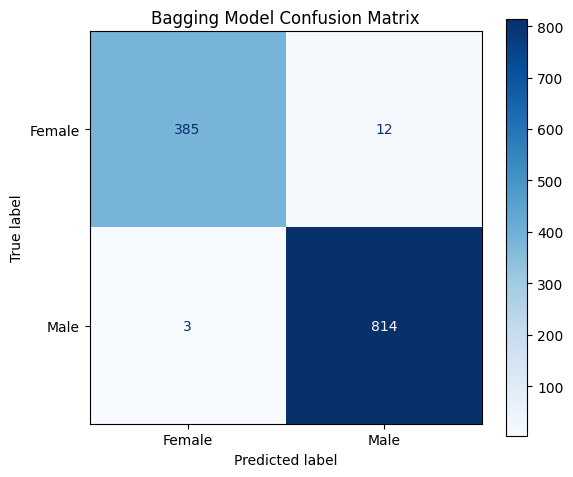

In [38]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    bagging_predictions,
    labels=["Female", "Male"],
    display_labels=["Female", "Male"],
    values_format="d",
    cmap="Blues",
    ax=ax,
)
ax.set_title("Bagging Model Confusion Matrix")
plt.tight_layout()
plt.show()

-----------------------------------
# Thanks for your time! :)